# EDA: how do failures change over time?

In this notebook I use the cleaned data from notebook 01 (446 sensors, 1,567 samples).
First I look at the fail rate over time, then at which sensors differ between passed and failed samples.

In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv("../data/processed/secom_clean.csv", parse_dates=["timestamp"])
sensor_cols = [c for c in df.columns if c.startswith("sensor_")]

print(df.shape)
print(df["label"].value_counts())

(1567, 448)
label
-1    1463
 1     104
Name: count, dtype: int64


In [4]:
# weekly number of samples and failures
weekly = (df.set_index("timestamp")
            .resample("W")["label"]
            .agg(n_samples="count", n_fails=lambda s: (s == 1).sum()))
weekly["fail_rate"] = weekly["n_fails"] / weekly["n_samples"]
print(weekly.round(3))

            n_samples  n_fails  fail_rate
timestamp                                
2008-07-20         13        3      0.231
2008-07-27         21        2      0.095
2008-08-03         48       10      0.208
2008-08-10        108       14      0.130
2008-08-17         51        7      0.137
2008-08-24        208       22      0.106
2008-08-31        169        7      0.041
2008-09-07        133        2      0.015
2008-09-14         95        4      0.042
2008-09-21        154        5      0.032
2008-09-28        166        4      0.024
2008-10-05        169       15      0.089
2008-10-12        138        8      0.058
2008-10-19         94        1      0.011


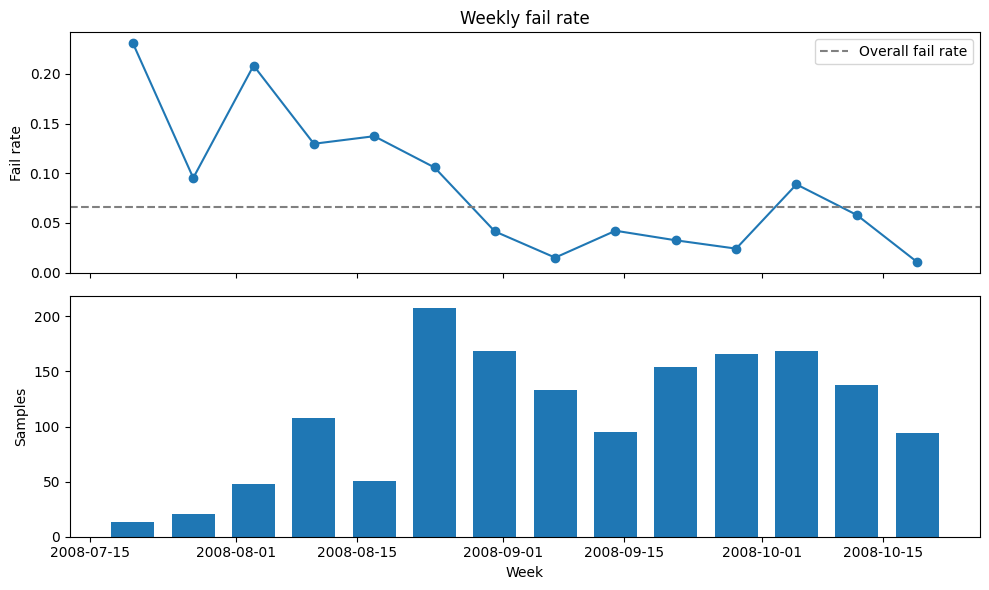

In [5]:
overall_rate = (df["label"] == 1).mean()

fig, axes = plt.subplots(2, 1, figsize=(10, 6), sharex=True)

# top: weekly fail rate
axes[0].plot(weekly.index, weekly["fail_rate"], marker="o")
axes[0].axhline(overall_rate, color="gray", linestyle="--", label="Overall fail rate")
axes[0].set_ylabel("Fail rate")
axes[0].set_title("Weekly fail rate")
axes[0].legend()

# bottom: how many samples each week
axes[1].bar(weekly.index, weekly["n_samples"], width=5)
axes[1].set_ylabel("Samples")
axes[1].set_xlabel("Week")

plt.tight_layout()
plt.show()

## Fail rate over time
The fail rate was high in July and August, around 10-20% in most weeks. After late August it dropped to
about 1-6%. The first three weeks only have 13, 21 and 48 samples, so those points jump around a lot
and I don't trust them much. The overall fail rate is 6.6% (dashed line).

In [ ]:
# compare fail rate before and after the cutoff date
from scipy.stats import chi2_contingency

cutoff = pd.Timestamp("2008-08-25")
early = df[df["timestamp"] < cutoff]
late = df[df["timestamp"] >= cutoff]

for name, part in [("early", early), ("late", late)]:
    print(name, "samples:", len(part), "fails:", (part["label"] == 1).sum(),
          "fail rate:", round((part["label"] == 1).mean(), 3))

# chi-square test
table = [[(early["label"] == 1).sum(), (early["label"] == -1).sum()],
         [(late["label"] == 1).sum(), (late["label"] == -1).sum()]]
chi2, p, _, _ = chi2_contingency(table)
print("p-value:", p)

early samples: 449 fails: 58 fail rate: 0.129
late samples: 1118 fails: 46 fail rate: 0.041
p-value: 5.055728943908669e-10


### Is the drop real?
I split the data at the end of August. Before: 449 samples, 12.9% failed. After: 1,118 samples, 4.1% failed.
The p-value from a chi-square test is about 5e-10, so this big a gap is very unlikely to be just luck.
I don't know why it dropped. It could be a process change, different products, or a change in how
samples were checked. I would need to ask an engineer.

This matters for modeling: if I split the data randomly, the training and test sets will mix early
and late samples. I also want to try splitting by time (train on early, test on late).

In [7]:
# daily samples and fails in the week with the spike (Sep 29 to Oct 5)
spike = df[(df["timestamp"] >= "2008-09-29") & (df["timestamp"] < "2008-10-06")]
daily = (spike.set_index("timestamp")
              .resample("D")["label"]
              .agg(n_samples="count", n_fails=lambda s: (s == 1).sum()))
daily["fail_rate"] = (daily["n_fails"] / daily["n_samples"]).round(3)
print(daily)

            n_samples  n_fails  fail_rate
timestamp                                
2008-09-29         21        1      0.048
2008-09-30         21        1      0.048
2008-10-01         17        1      0.059
2008-10-02         35        5      0.143
2008-10-03         25        0      0.000
2008-10-04         18        1      0.056
2008-10-05         32        6      0.188


### The spike in early October
The week of Oct 5 had 15 failures out of 169 samples. Most of them came from two days: Oct 2 (5 out of 35)
and Oct 5 (6 out of 32). Oct 3 had none. So it looks like two bad days, not a bad week.
But I'm looking at about 90 days and picking the worst ones, so some extreme days are expected by chance.

In [8]:
from scipy.stats import mannwhitneyu, false_discovery_control

def screen_sensors(data, min_n=20):
    """Compare each sensor between failed and passed samples."""
    rows = []
    fail = data[data["label"] == 1]
    ok = data[data["label"] == -1]
    for s in sensor_cols:
        a = fail[s].dropna()
        b = ok[s].dropna()
        if len(a) < min_n or len(b) < min_n:
            continue
        u, p = mannwhitneyu(a, b, alternative="two-sided")
        auc = u / (len(a) * len(b))   # 0.5 = no difference
        rows.append((s, auc, p))
    res = pd.DataFrame(rows, columns=["sensor", "auc", "p"])
    res["p_adj"] = false_discovery_control(res["p"])   # correct for many tests
    res["effect"] = (res["auc"] - 0.5).abs()
    return res.sort_values("p_adj")

all_res = screen_sensors(df)
late_res = screen_sensors(df[df["timestamp"] >= cutoff])

print("All data, top 10:")
print(all_res.head(10).round(4))
print("\nLate period only, top 10:")
print(late_res.head(10).round(4))

# sensors that rank in the top 20 in both
both = set(all_res.head(20)["sensor"]) & set(late_res.head(20)["sensor"])
print("\nIn the top 20 of both:", sorted(both))

All data, top 10:
         sensor     auc       p   p_adj  effect
54    sensor_59  0.6920  0.0000  0.0000  0.1920
93   sensor_103  0.6682  0.0000  0.0000  0.1682
390  sensor_519  0.6739  0.0000  0.0001  0.1739
203  sensor_247  0.6747  0.0000  0.0001  0.1747
388  sensor_510  0.6360  0.0000  0.0003  0.1360
367  sensor_477  0.6213  0.0000  0.0026  0.1213
179  sensor_205  0.6193  0.0000  0.0027  0.1193
116  sensor_129  0.6190  0.0000  0.0027  0.1190
26    sensor_28  0.3829  0.0001  0.0034  0.1171
298  sensor_385  0.6335  0.0002  0.0066  0.1335

Late period only, top 10:
         sensor     auc       p   p_adj  effect
90   sensor_100  0.6332  0.0020  0.1004  0.1332
50    sensor_55  0.3603  0.0015  0.1004  0.1397
255  sensor_319  0.6428  0.0010  0.1004  0.1428
107  sensor_121  0.6352  0.0019  0.1004  0.1352
265  sensor_336  0.6425  0.0011  0.1004  0.1425
110  sensor_124  0.6355  0.0018  0.1004  0.1355
268  sensor_339  0.6435  0.0010  0.1004  0.1435
349  sensor_455  0.6419  0.0011  0.1004  0.

In [9]:
# drift check: among PASSED samples only, do the top sensors differ between early and late?
top = all_res.head(10)["sensor"].tolist()
ok = df[df["label"] == -1]

rows = []
for s in top:
    e = ok.loc[ok["timestamp"] < cutoff, s].dropna()
    l = ok.loc[ok["timestamp"] >= cutoff, s].dropna()
    if len(e) < 20 or len(l) < 20:
        continue
    u, p = mannwhitneyu(e, l)
    rows.append((s, len(e), len(l), u / (len(e) * len(l)), p))

drift = pd.DataFrame(rows, columns=["sensor", "n_early", "n_late", "auc_early_vs_late", "p"])
print(drift.round(4))

       sensor  n_early  n_late  auc_early_vs_late    p
0   sensor_59      391    1065             0.7535  0.0
1  sensor_103      391    1070             0.8394  0.0
2  sensor_519      288     493             0.7780  0.0
3  sensor_247      288     493             0.7809  0.0
4  sensor_510      391    1070             0.7512  0.0
5  sensor_477      391    1066             0.5779  0.0
6  sensor_205      391    1066             0.5754  0.0
7  sensor_129      385    1069             0.7068  0.0
8   sensor_28      391    1071             0.1671  0.0
9  sensor_385      288     493             0.6847  0.0


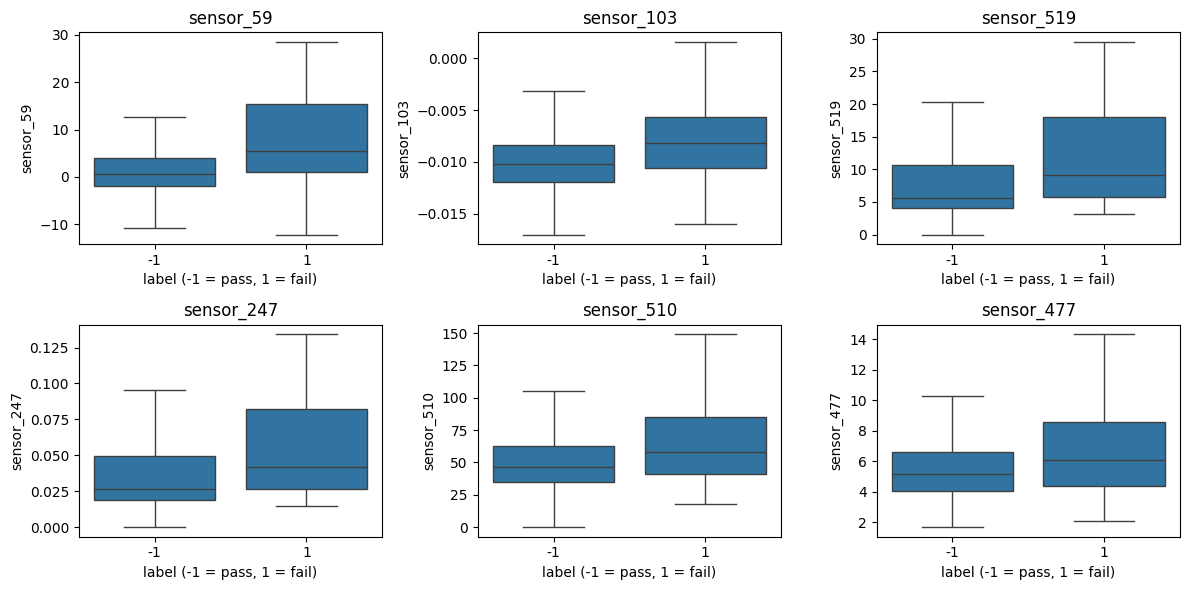

In [10]:
# passed vs failed distributions for the top 6 sensors (outliers hidden to keep the plot readable)
top6 = all_res.head(6)["sensor"].tolist()
fig, axes = plt.subplots(2, 3, figsize=(12, 6))
for ax, s in zip(axes.ravel(), top6):
    sns.boxplot(data=df, x="label", y=s, ax=ax, showfliers=False)
    ax.set_title(s)
    ax.set_xlabel("label (-1 = pass, 1 = fail)")
plt.tight_layout()
plt.show()

## Which sensors differ between pass and fail?
I compared each sensor between passed and failed samples with a Mann-Whitney test, and corrected for
testing 446 sensors at once. About 10 sensors stay significant (AUC 0.62-0.69), for example sensor_59,
103, 519, 247 and 510. In the boxplots the failed samples read higher, but the boxes overlap a lot,
so no single sensor can separate pass from fail.

### But these sensors also drift over time
Most failures happen early, so I checked whether the sensors change over time in passed samples only.
They do: for all 10 top sensors, early and late readings are very different (AUC 0.58 to 0.84, and 0.17
for sensor_28). In every case the direction matches the failure pattern. For example sensor_103 reads
higher early, and failed samples also read higher. So part of the link to failure may just be time.
I can't call these sensors causes of failure yet.

In [11]:
# remove slow drift: subtract a rolling median (about one week of samples) from each sensor
df_sorted = df.sort_values("timestamp").reset_index(drop=True)
detr = df_sorted.copy()
for s in sensor_cols:
    trend = df_sorted[s].rolling(window=101, center=True, min_periods=30).median()
    detr[s] = df_sorted[s] - trend

detr_res = screen_sensors(detr).reset_index(drop=True)
detr_res["rank"] = detr_res.index + 1
print("After removing drift, top 10:")
print(detr_res.head(10).round(4))

# where did the earlier top 10 end up?
old_top = all_res.head(10)["sensor"].tolist()
print("\nEarlier top 10 after removing drift:")
print(detr_res.set_index("sensor").reindex(old_top)[["rank", "auc", "p_adj"]].round(4))

After removing drift, top 10:
       sensor     auc       p   p_adj  effect  rank
0   sensor_59  0.6127  0.0001  0.0268  0.1127     1
1  sensor_477  0.6132  0.0001  0.0268  0.1132     2
2  sensor_205  0.6093  0.0002  0.0285  0.1093     3
3  sensor_341  0.6050  0.0003  0.0306  0.1050     4
4  sensor_336  0.6051  0.0003  0.0306  0.1051     5
5  sensor_343  0.5989  0.0007  0.0472  0.0989     6
6  sensor_479  0.5989  0.0007  0.0472  0.0989     7
7   sensor_21  0.5978  0.0009  0.0496  0.0978     8
8  sensor_207  0.5956  0.0011  0.0550  0.0956     9
9  sensor_200  0.5914  0.0018  0.0765  0.0914    10

Earlier top 10 after removing drift:
            rank     auc   p_adj
sensor                          
sensor_59      1  0.6127  0.0268
sensor_103    71  0.5515  0.4727
sensor_519   178  0.5415  0.6364
sensor_247   177  0.5414  0.6364
sensor_510    57  0.5561  0.4335
sensor_477     2  0.6132  0.0268
sensor_205     3  0.6093  0.0285
sensor_129    78  0.5506  0.4802
sensor_28    194  0.4696  0.69

### After removing the drift
To take time out of the picture, I subtracted a rolling median (about one week of samples) from each
sensor and ran the test again. Most of the earlier top sensors lost their signal: sensor_103, 510, 129,
519, 247, 28 and 385 dropped to rank 50 or lower. So they mostly looked related to failure
because they drift over time. Three sensors stayed at the top: sensor_59, sensor_477 and sensor_205
(adjusted p about 0.03). Several others are borderline (adjusted p between 0.03 and 0.05).

Even for the best sensors, the AUC is only about 0.61, so the signal is weak. I shouldn't expect a very
strong model from these sensors alone.

In [12]:
# is the result stable if I change the window size?
def top_after_detrend(window, n=10):
    out = df_sorted.copy()
    for c in sensor_cols:
        out[c] = df_sorted[c] - df_sorted[c].rolling(window, center=True, min_periods=30).median()
    return screen_sensors(out).head(n)["sensor"].tolist()

base = set(detr_res.head(10)["sensor"])
for w in [51, 201]:
    t = set(top_after_detrend(w))
    print(f"window {w}: {len(base & t)} of 10 same -> {sorted(base & t)}")

window 51: 10 of 10 same -> ['sensor_200', 'sensor_205', 'sensor_207', 'sensor_21', 'sensor_336', 'sensor_341', 'sensor_343', 'sensor_477', 'sensor_479', 'sensor_59']
window 201: 8 of 10 same -> ['sensor_205', 'sensor_21', 'sensor_336', 'sensor_341', 'sensor_343', 'sensor_477', 'sensor_479', 'sensor_59']


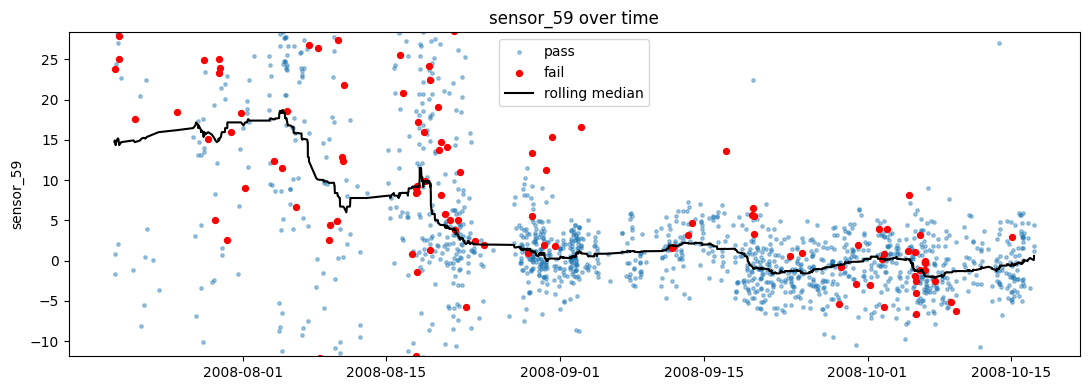

In [13]:
# sensor_59 over time, with failed samples in red
s = "sensor_59"
d = df_sorted[["timestamp", s, "label"]].dropna()
trend = d[s].rolling(101, center=True, min_periods=30).median()

fig, ax = plt.subplots(figsize=(11, 4))
passed = d[d["label"] == -1]
failed = d[d["label"] == 1]
ax.scatter(passed["timestamp"], passed[s], s=6, alpha=0.4, label="pass")
ax.scatter(failed["timestamp"], failed[s], s=18, color="red", label="fail")
ax.plot(d["timestamp"], trend, color="black", label="rolling median")
ax.set_ylim(d[s].quantile(0.01), d[s].quantile(0.99))   # cut extreme outliers for readability
ax.set_title(f"{s} over time")
ax.set_ylabel(s)
ax.legend()
plt.tight_layout()
plt.show()

### Does the result hold up?
I tried other window sizes for the rolling median. With 51 samples, the top 10 sensors are exactly the same.
With 201 samples, 8 of 10 are the same. sensor_59, 477 and 205 are in the top 10 every time,
so the result doesn't depend much on the window size.

### sensor_59 over time
The plot shows two different periods. Before about Aug 20 the readings are high (rolling median around
15 at first, then around 8) and very spread out. After that they drop to around 0-2 and are much tighter.
Most failures are in the early, noisy period, and many of them have high readings. In the later period
the failed samples mostly sit inside the passed ones, with a few high outliers. Something seems to have
changed in the process around Aug 20, but I don't know what. (The y-axis is cut at the 1st and 99th
percentile, so some extreme points are not shown.)